In [ ]:
!pip install mlflow

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import mlflow
import mlflow.sklearn

import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv("/content/Breast_Cancer.csv")

In [ ]:
df.head()

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive


In [ ]:
df.shape

(4024, 16)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Age                     4024 non-null   int64 
 1   Race                    4024 non-null   object
 2   Marital Status          4024 non-null   object
 3   T Stage                 4024 non-null   object
 4   N Stage                 4024 non-null   object
 5   6th Stage               4024 non-null   object
 6   differentiate           4024 non-null   object
 7   Grade                   4024 non-null   object
 8   A Stage                 4024 non-null   object
 9   Tumor Size              4024 non-null   int64 
 10  Estrogen Status         4024 non-null   object
 11  Progesterone Status     4024 non-null   object
 12  Regional Node Examined  4024 non-null   int64 
 13  Reginol Node Positive   4024 non-null   int64 
 14  Survival Months         4024 non-null   int64 
 15  Stat

In [ ]:
df["Status"].value_counts()

,count
Status,
Alive,3408
Dead,616


In [ ]:
df["Status"].value_counts(normalize=True) * 100

,proportion
Status,
Alive,84.691849
Dead,15.308151


In [ ]:
df.isnull().sum()

,0
Age,0
Race,0
Marital Status,0
T Stage,0
N Stage,0
6th Stage,0
differentiate,0
Grade,0
A Stage,0
Tumor Size,0


In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df.duplicated().sum()

np.int64(1)

In [ ]:
df = df.drop_duplicates()

In [ ]:
categorical_columns = df.select_dtypes(include=["object"]).columns
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
Index(['Race', 'Marital Status', 'T Stage ', 'N Stage', '6th Stage',
       'differentiate', 'Grade', 'A Stage', 'Estrogen Status',
       'Progesterone Status', 'Status'],
      dtype='object')

Numerical columns:
Index(['Age', 'Tumor Size', 'Regional Node Examined', 'Reginol Node Positive',
       'Survival Months'],
      dtype='object')


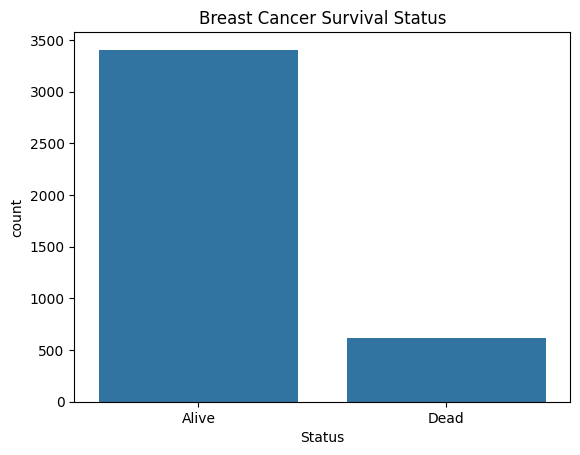

In [ ]:
sns.countplot(data=df, x="Status")
plt.title("Breast Cancer Survival Status")
plt.show()

In [ ]:
df[numerical_columns].describe()

,Age,Tumor Size,Regional Node Examined,Reginol Node Positive,Survival Months
count,4023.000000,4023.000000,4023.000000,4023.000000,4023.000000
mean,53.969923,30.477007,14.358439,4.158837,71.301765
std,8.963118,21.121253,8.100241,5.109724,22.923009
min,30.000000,1.000000,1.000000,1.000000,1.000000
25%,47.000000,16.000000,9.000000,1.000000,56.000000
50%,54.000000,25.000000,14.000000,2.000000,73.000000
75%,61.000000,38.000000,19.000000,5.000000,90.000000
max,69.000000,140.000000,61.000000,46.000000,107.000000


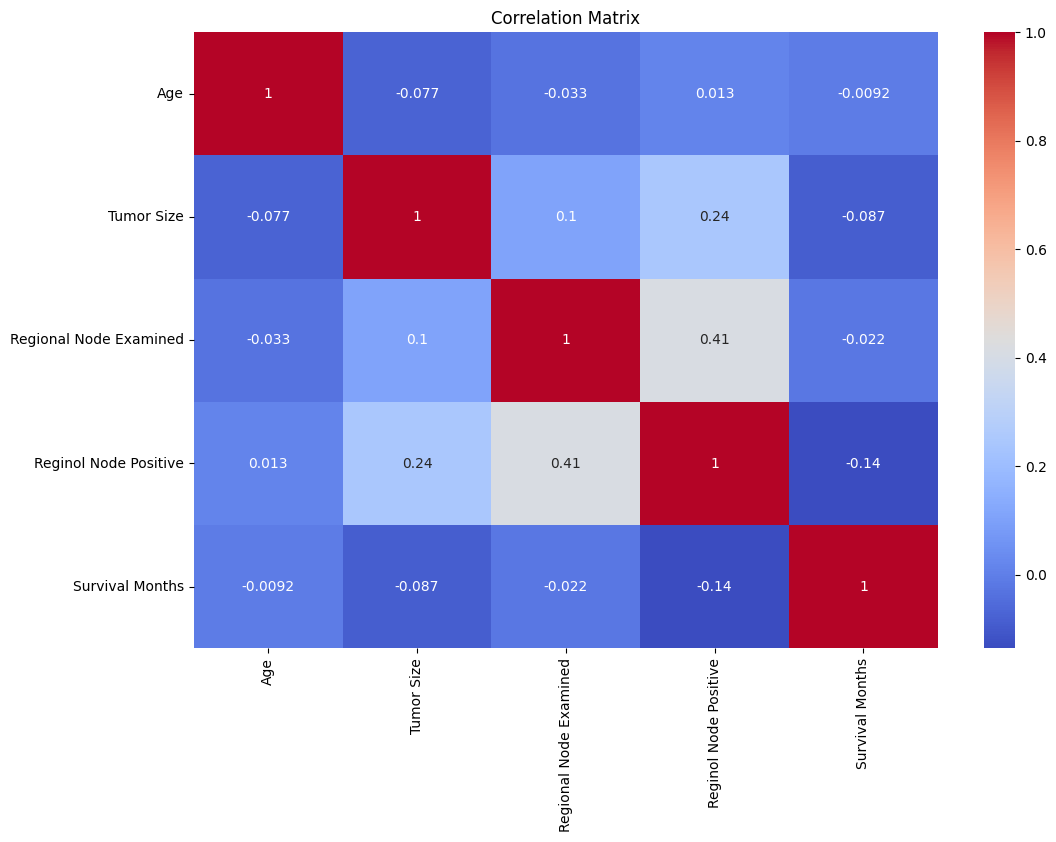

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df[numerical_columns].corr(), annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

In [ ]:
X = df.drop("Status", axis=1)
y = df["Status"]

In [ ]:
y = y.map({
"Alive": 0,
"Dead": 1
})


In [ ]:
y.value_counts()

,count
Status,
0,3407
1,616


In [ ]:
X = df.drop(["Status", "Survival Months"], axis=1)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split( X,
y,
test_size=0.2,
random_state=42, stratify=y
)


In [ ]:
categorical_features = X.select_dtypes(include=["object"]).columns
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns

In [ ]:
numeric_transformer = Pipeline( steps=[
("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())
]
)

categorical_transformer = Pipeline( steps=[
("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))
]
)


In [ ]:
preprocessor = ColumnTransformer( transformers=[
("num", numeric_transformer, numerical_features),
("cat", categorical_transformer, categorical_features)
]
)


In [ ]:
logistic_model = Pipeline( steps=[
("preprocessor", preprocessor),
("model", LogisticRegression(max_iter=1000))
]
)

logistic_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Age', 'Tumor Size', 'Regional Node Examined', 'Reginol Node Positive'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['Race', 'Marital Status', 'T Stage ', 'N Stage', '6th Stage',
       'differentiate', 'Grade', 'A Stage', 'Estrogen Status',
       'Progesterone Status'],
      dtype='object'))])),
                ('model', LogisticRegression(max_iter=1000))])

In [ ]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=100, random_state=42))
])

rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Age', 'Tumor Size', 'Regional Node Examined', 'Reginol Node Positive'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['Race', 'Marital Status', 'T Stage ', 'N Stage', '6th Stage',
       'differentiate', 'Grade', 'A Stage', 'Estrogen Status',
       'Progesterone Status'],
      dtype='object'))])),
                ('model', RandomForestClassifier(random_state=42))])

In [ ]:
xgb_model = Pipeline( steps=[
("preprocessor", preprocessor), ("model", XGBClassifier(
n_estimators=100, max_depth=5,
learning_rate=0.1, random_state=42,
eval_metric="logloss"
))
]
)

xgb_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Age', 'Tumor Size', 'Regional Node Examined', 'Reginol Node Positive'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [ ]:
models = {
"Logistic Regression": logistic_model, "Random Forest": rf_model,
"XGBoost": xgb_model
}


In [ ]:
results = []
for name, model in models.items(): y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

results.append({
"Model": name,
"Accuracy": accuracy_score(y_test, y_pred), "Precision": precision_score(y_test, y_pred), "Recall": recall_score(y_test, y_pred),
"F1 Score": f1_score(y_test, y_pred),
"ROC AUC": roc_auc_score(y_test, y_prob)
})
results_df = pd.DataFrame(results)
results_df


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,XGBoost,0.847205,0.5,0.154472,0.236025,0.717164


In [ ]:
import mlflow
import mlflow.sklearn

mlflow.set_experiment("Breast_Cancer_Prediction")

2026/11/01 14:37:07 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/01 14:37:07 INFO mlflow.store.db.utils: Updating database tables
2026/11/01 14:37:17 INFO mlflow.tracking.fluent: Experiment with name 'Breast_Cancer_Prediction' does not exist. Creating a new experiment.


<Experiment: artifact_location='/content/mlruns/1', creation_time=1793543837044, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1793543837044, lifecycle_stage='active', name='Breast_Cancer_Prediction', tags={}, trace_location=None, workspace='default'>

In [ ]:
for name, model in models.items():
    with mlflow.start_run(run_name=name):
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        roc_auc = roc_auc_score(y_test, y_prob)

        mlflow.log_metric("accuracy", accuracy)
        mlflow.log_metric("precision", precision)
        mlflow.log_metric("recall", recall)
        mlflow.log_metric("f1_score", f1)
        mlflow.log_metric("roc_auc", roc_auc)

        mlflow.sklearn.log_model(
            model,
            "model",
            serialization_format="cloudpickle"
        )

        print(name)
        print("Accuracy:", accuracy)
        print("F1:", f1)
        print("ROC AUC:", roc_auc)
        print("-" * 30)

2026/11/01 14:37:17 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/01 14:37:18 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logistic Regression
Accuracy: 0.8571428571428571
F1: 0.23841059602649006
ROC AUC: 0.73394845385404
------------------------------


2026/11/01 14:37:29 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/01 14:37:29 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest
Accuracy: 0.8335403726708075
F1: 0.20238095238095238
ROC AUC: 0.6820208378036859
------------------------------


2026/11/01 14:37:43 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/01 14:37:43 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGBoost
Accuracy: 0.8472049689440994
F1: 0.2360248447204969
ROC AUC: 0.7171637698781681
------------------------------


In [39]:
# Get the experiment
experiment = mlflow.get_experiment_by_name("Breast_Cancer_Prediction")

# Retrieve all recorded runs
runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["metrics.roc_auc DESC"]
)

# Display model performance
display(runs[[
    "run_id",
    "metrics.accuracy",
    "metrics.precision",
    "metrics.recall",
    "metrics.f1_score",
    "metrics.roc_auc"
]])

# Identify the best model
best_run = runs.iloc[0]

best_run_id = best_run["run_id"]

print("Best Model Run ID:", best_run_id)
print("Best ROC-AUC:", best_run["metrics.roc_auc"])
print("Best Model URI:", f"runs:/{best_run_id}/model")

,run_id,metrics.accuracy,metrics.precision,metrics.recall,metrics.f1_score,metrics.roc_auc
0,5c593d67f2d346eb935fee7c362eaf04,0.857143,0.642857,0.146341,0.238411,0.733948
1,618246e1e5754d428eec7ad706a5c6bc,0.847205,0.500000,0.154472,0.236025,0.717164
2,b67c92f233764acb9fffe844b1387bd3,0.833540,0.377778,0.138211,0.202381,0.682021


Best Model Run ID: 5c593d67f2d346eb935fee7c362eaf04
Best ROC-AUC: 0.73394845385404
Best Model URI: runs:/5c593d67f2d346eb935fee7c362eaf04/model


In [40]:
# Register the best model in MLflow Model Registry

model_name = "Breast_Cancer_Prediction_Model"

model_uri = f"runs:/{best_run_id}/model"

registered_model = mlflow.register_model(
    model_uri=model_uri,
    name=model_name
)

print("Model registered successfully!")
print("Registered Model Name:", registered_model.name)
print("Model Version:", registered_model.version)

Successfully registered model 'Breast_Cancer_Prediction_Model'.
2026/11/01 14:47:17 WARNING mlflow.tracking._model_registry.fluent: Run with id 5c593d67f2d346eb935fee7c362eaf04 has no artifacts at artifact path 'model', registering model based on models:/m-16e85403eb3d4283913b8d55885dd9ed instead


Model registered successfully!
Registered Model Name: Breast_Cancer_Prediction_Model
Model Version: 1


Created version '1' of model 'Breast_Cancer_Prediction_Model'.


In [41]:
# Verify registered model

client = mlflow.tracking.MlflowClient()

for version in client.search_model_versions(
    f"name='{model_name}'"
):
    print("Model Name:", version.name)
    print("Version:", version.version)
    print("Run ID:", version.run_id)
    print("Status:", version.status)
    print("-" * 40)

Model Name: Breast_Cancer_Prediction_Model
Version: 1
Run ID: 5c593d67f2d346eb935fee7c362eaf04
Status: READY
----------------------------------------


In [42]:
# Load the registered model
registered_model_uri = "models:/Breast_Cancer_Prediction_Model/1"

loaded_model = mlflow.pyfunc.load_model(registered_model_uri)

# Generate predictions
predictions = loaded_model.predict(X_test.head(5))

print("Predictions:", predictions)
print("Actual Values:", y_test.head(5).values)

Predictions: [0 0 0 0 0]
Actual Values: [0 1 0 0 0]


In [43]:
import os
import requests
import base64
from getpass import getpass
from google.colab import files

# GitHub details
GITHUB_USERNAME = input("Enter your GitHub username: ")
REPO_NAME = "MLOPS-Experiment-06"

# Securely enter your token
TOKEN = getpass("Paste your GitHub token: ")

# Upload notebook and dataset
print("Upload your completed .ipynb notebook and Breast_Cancer.csv")

uploaded = files.upload()

# Create project files
readme = """
# Breast Cancer Prediction using MLflow

## Aim
To develop and evaluate machine learning models for predicting
breast cancer survival status and implement MLflow for experiment
tracking, model comparison, and model registration.

## Models Used
1. Logistic Regression
2. Random Forest
3. XGBoost

## Technologies
- Python
- Pandas
- NumPy
- Scikit-learn
- XGBoost
- MLflow
- Google Colab

## MLflow
MLflow was used to track model performance, compare experiments,
and register the best-performing model.

## Best Model
Logistic Regression

## Best ROC-AUC
0.7339

## Model Accuracy
85.71%

## Registered Model
Breast_Cancer_Prediction_Model
"""

requirements = """
pandas
numpy
matplotlib
seaborn
scikit-learn
xgboost
mlflow
"""

with open("/content/README.md", "w") as f:
    f.write(readme)

with open("/content/requirements.txt", "w") as f:
    f.write(requirements)

# GitHub API
headers = {
    "Authorization": f"Bearer {TOKEN}",
    "Accept": "application/vnd.github+json"
}

repo_url = f"https://api.github.com/repos/{GITHUB_USERNAME}/{REPO_NAME}"

# Check repository
response = requests.get(repo_url, headers=headers)

if response.status_code != 200:
    raise Exception("Repository not found. Check your username and repository name.")

# Upload files
project_files = list(uploaded.keys()) + [
    "README.md",
    "requirements.txt"
]

for filename in project_files:

    filepath = os.path.join("/content", filename)

    with open(filepath, "rb") as f:
        content = base64.b64encode(f.read()).decode("utf-8")

    upload_url = (
        f"https://api.github.com/repos/"
        f"{GITHUB_USERNAME}/{REPO_NAME}/contents/{filename}"
    )

    data = {
        "message": f"Upload {filename}",
        "content": content,
        "branch": "main"
    }

    result = requests.put(
        upload_url,
        headers=headers,
        json=data
    )

    if result.status_code in [200, 201]:
        print("Uploaded successfully:", filename)
    else:
        print("Upload failed:", filename)
        print(result.json())

print("\nPROJECT UPLOAD COMPLETED!")
print(f"GitHub Repository: https://github.com/{GITHUB_USERNAME}/{REPO_NAME}")

Enter your GitHub username: Bhushan24-chowdary
Paste your GitHub token: ··········
Upload your completed .ipynb notebook and Breast_Cancer.csv


Saving mlops_exp_06.ipynb to mlops_exp_06.ipynb
Uploaded successfully: mlops_exp_06.ipynb
Uploaded successfully: README.md
Uploaded successfully: requirements.txt

PROJECT UPLOAD COMPLETED!
GitHub Repository: https://github.com/Bhushan24-chowdary/MLOPS-Experiment-06


In [44]:
results = []

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8571,0.6429,0.1463,0.2384,0.7339
1,Random Forest,0.8335,0.3778,0.1382,0.2024,0.6820
2,XGBoost,0.8472,0.5000,0.1545,0.2360,0.7172


In [45]:
registered_model_uri = "models:/Breast_Cancer_Prediction_Model/1"

loaded_model = mlflow.pyfunc.load_model(registered_model_uri)

predictions = loaded_model.predict(X_test.head(5))

print("Predictions:", predictions)
print("Actual Values:", y_test.head(5).values)

Predictions: [0 0 0 0 0]
Actual Values: [0 1 0 0 0]


In [46]:
print("BEST MODEL DETAILS")
print("--------------------------")
print("Best Model: Logistic Regression")
print("Best ROC-AUC:", best_run["metrics.roc_auc"])
print("Best Accuracy:", best_run["metrics.accuracy"])
print("Model Name:", model_name)
print("Model Version:", registered_model.version)
print("Model Status:", registered_model.status)

BEST MODEL DETAILS
--------------------------
Best Model: Logistic Regression
Best ROC-AUC: 0.73394845385404
Best Accuracy: 0.8571428571428571
Model Name: Breast_Cancer_Prediction_Model
Model Version: 1
Model Status: READY
